# Práctica 4 · Extra: Detección de matrículas con técnicas clásicas

---

1. **Multiescala:** Procesa la imagen a 3 resoluciones distintas (640, 1100, 1920) para detectar tanto coches lejanos como cercanos.
2. **Triangulación de características:** Genera regiones candidatas buscando tres patrones distintos:
   - Texto (Operación Morfológica *Black-hat* + Gradiente Sobel).
   - Bordes fuertes (Filtro Bilateral + Canny).
   - Color reflectante (Filtro HSV para zonas blancas/desaturadas y brillantes).
3. **Verificación geométrica y de contenido:** Filtra los contornos por área y rectangularidad, y los verifica internamente mediante el recuento de componentes conectadas (caracteres).

In [ ]:
import json
import random
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

#DATASET = Path("C:/Users/User/Downloads/dataset")
DATASET = Path("C:/Users/User/Desktop/VC/P4/dataset_1920")
SPLIT = "test"
IOU_ACIERTO = 0.5 # Consideramos acierto si la intersección sobre la unión es >= 50%
ESCALAS = (640, 1100, 1920)

# Contrarrestar sombras y brillos
CLAHE = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

def rect_k(w, h):
    """Crea un elemento estructurante rectangular para operaciones morfológicas."""
    return cv2.getStructuringElement(cv2.MORPH_RECT, (w, h))


def iou(a, b):
    """Calcula la Intersección sobre la Unión (IoU) entre dos cajas delimitadoras."""
    ix = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    
    inter = ix * iy
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    
    if union > 0:
        return inter / union
    else:
        return 0.0


def cargar_coco(dataset, split):
    """Carga las anotaciones Ground Truth (cajas reales) desde el archivo JSON de formato COCO."""
    nombre_json = {"train": "train_coco.json", "validation": "val_coco.json", "test": "test_coco.json"}[split]
    ruta_json = dataset / "annotations" / nombre_json

    if not ruta_json.exists():
        print(f"No se encuentra el JSON en: {ruta_json}")
        return []
    
    coco = json.loads(ruta_json.read_text(encoding="utf-8"))
    cajas = {}

    # coordenadas de todas las cajas
    for a in coco["annotations"]:
        x, y, w, h = a["bbox"]
        cajas.setdefault(a["image_id"], []).append([x, y, x + w, y + h])
    
    
    resultado = []
    # asocia cada caja con la ruta de su imagen
    for f in coco["images"]:
        ruta_imagen = str(dataset / split / "images" / f["file_name"])
        cajas_imagen = cajas.get(f["id"], [])
        resultado.append((ruta_imagen, cajas_imagen))
        
    return resultado


def pasos_caracteres(gris):
    """
    Busca patrones de texto (letras oscuras sobre fondo claro).
    1. CLAHE para igualar la iluminación.
    2. Black-Hat (cierre - imagen original) para extraer elementos oscuros pequeños (caracteres).
    3. Sobel X para destacar bordes verticales típicos de las letras.
    4. Cierre morfológico para fusionar los caracteres en un solo bloque rectangular.
    """
    eq = CLAHE.apply(gris)

    blackhat = cv2.morphologyEx(eq, cv2.MORPH_BLACKHAT, rect_k(13, 5))
    
    gx = np.abs(cv2.Sobel(blackhat, cv2.CV_32F, 1, 0, ksize=3))
    gx = cv2.normalize(gx, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    gx = cv2.GaussianBlur(gx, (5, 5), 0)
    
    gx = cv2.morphologyEx(gx, cv2.MORPH_CLOSE, rect_k(17, 5))
    _, binaria = cv2.threshold(gx, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    binaria = cv2.morphologyEx(binaria, cv2.MORPH_OPEN, rect_k(3, 3), iterations=2)
    
    claro = cv2.morphologyEx(eq, cv2.MORPH_CLOSE, rect_k(3, 3))
    _, claro = cv2.threshold(claro, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    claro = cv2.dilate(claro, rect_k(5, 5))

    final = cv2.dilate(cv2.bitwise_and(binaria, claro), rect_k(5, 3))
    
    return {"CLAHE": eq, "Black-hat": blackhat, "Sobel X + cierre": gx, 
            "Otsu + apertura": binaria, "Zonas claras": claro, "Mascara final": final}


def pasos_bordes(gris):
    """
    Busca formas bien delimitadas.
    Usa un filtro bilateral para eliminar ruido sin emborronar bordes, aplica Canny,
    y cierra los contornos discontinuos con una operación morfológica.
    """
    suave = cv2.bilateralFilter(gris, 9, 50, 50)
    bordes = cv2.Canny(suave, 50, 150)
    return cv2.morphologyEx(bordes, cv2.MORPH_CLOSE, rect_k(3, 3))


def mascara_blanco(img):
    """
    Filtra la imagen por color en el espacio HSV.
    Aísla las áreas con muy baja saturación y alto valor/brillo (fondo de la placa).
    """
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    m = cv2.inRange(hsv, (0, 0, 140), (180, 60, 255))
    return cv2.morphologyEx(m, cv2.MORPH_OPEN, rect_k(3, 3))


def cajas_de_mascara(mascara, area_min=150, retr=cv2.RETR_EXTERNAL):
    """Extrae contornos de las máscaras binarias y filtra aquellos que no tienen proporción de rectángulo."""
    salida = []
    contornos, _ = cv2.findContours(mascara, retr, cv2.CHAIN_APPROX_SIMPLE)
    
    for c in contornos:
        area = cv2.contourArea(c)
       
        if area < area_min:
            continue

        (_, _), (rw, rh), _ = cv2.minAreaRect(c)
        largo, corto = max(rw, rh), min(rw, rh)

        if corto < 6 or not 2.0 <= largo / corto <= 7.5: # Proporción de matrícula
            continue
        if area / (rw * rh + 1e-6) < 0.45: # Tolerancia de rectangularidad
            continue

        x, y, w, h = cv2.boundingRect(c)
        salida.append([x, y, x + w, y + h])

    return salida


def contar_caracteres(gris, caja):
    """
    Verificación mediante Análisis de Componentes Conectadas (Blobs).
    Recorta la caja sospechosa, la binariza, y cuenta cuántas manchas aisladas
    de tamaño de letra existen en su interior.
    """
    x1, y1, x2, y2 = [int(round(v)) for v in caja[:4]]
    recorte = gris[max(0, y1):y2, max(0, x1):x2]

    if recorte.size == 0 or recorte.shape[0] < 6:
        return 0
    
    f = 48 / recorte.shape[0]
    recorte = cv2.resize(recorte, (max(1, int(recorte.shape[1] * f)), 48))
    recorte = CLAHE.apply(recorte)

    _, binaria = cv2.threshold(recorte, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    n, _, stats, cent = cv2.connectedComponentsWithStats(binaria, connectivity=8)
    
    H, W = binaria.shape
    alturas, ys = [], []

    for i in range(1, n):
        x, y, w, h, a = stats[i]

        if 0.30 * H <= h <= 0.95 * H and w <= 0.25 * W and w >= 2 and a >= 0.15 * w * h:
            alturas.append(h)
            ys.append(cent[i][1])

    if len(alturas) < 3:
        return len(alturas)
    
    med_h, med_y = np.median(alturas), np.median(ys)
    return sum(abs(h - med_h) <= 0.25 * med_h and abs(y - med_y) <= 0.2 * H for h, y in zip(alturas, ys))


def puntuar(gris, caja):
    """Asigna un score de confianza basado en la proporción geométrica y el número de letras."""
    w, h = caja[2] - caja[0], caja[3] - caja[1]
    n = contar_caracteres(gris, caja)

    if n < 4:
        return 0.0
    
    if 5 <= n <= 9:
        p_car = 1.0
    else:
        p_car = 0.6

    p_prop = max(0.0, 1 - abs(np.log((w / h) / 4.7)) / np.log(3))
    return 0.6 * p_car + 0.4 * p_prop


def nms(cajas, umbral=0.3):
    """Supresión de No Máximos: Elimina detecciones duplicadas de una misma matrícula."""
    final = []
    for c in sorted(cajas, key=lambda c: -c[4]):
        if all(iou(c, f) < umbral for f in final):
            final.append(c)
    return final

def detectar_mejorado(img, umbral=0.5, max_det=5):
    """Procesa multiescala, extrae cajas, verifica y devuelve los mejores candidatos."""
    H, W = img.shape[:2]
    gris_full = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    candidatos = []
    
    for ancho in ESCALAS:
        f = min(1.0, ancho / W)
        
        if f < 1:
            peq = cv2.resize(img, (int(W * f), int(H * f)), interpolation=cv2.INTER_AREA)
        else:
            peq = img
            
        gris = cv2.cvtColor(peq, cv2.COLOR_BGR2GRAY)
        
        cajas = cajas_de_mascara(pasos_caracteres(gris)["Mascara final"])
        cajas += cajas_de_mascara(pasos_bordes(gris), retr=cv2.RETR_LIST)
        cajas += cajas_de_mascara(mascara_blanco(peq))
        
        for x1, y1, x2, y2 in cajas:
            caja_reescalada = [x1 / f, y1 / f, x2 / f, y2 / f]
            candidatos.append(caja_reescalada)
            
        if f == 1.0:
            break
            
    aceptadas = []
    for c in candidatos:
        p = puntuar(gris_full, c)
        if p >= umbral:
            aceptadas.append([c[0], c[1], c[2], c[3], p])
            
    return nms(aceptadas)[:max_det]


def dibujar_evaluacion(img, gts, dets):
    """Dibuja en Verde el Ground Truth, en Azul los Aciertos y en Rojo los Errores."""
    out = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    g = max(2, img.shape[1] // 400)

    for b in gts:
        cv2.rectangle(out, (int(b[0]), int(b[1])), (int(b[2]), int(b[3])), (0, 200, 0), g)

    for k, d in enumerate(dets):
        ok = any(iou(d, b) >= IOU_ACIERTO for b in gts)
        color = (40, 110, 255) if ok else (255, 40, 40)
        
        cv2.rectangle(out, (int(d[0]), int(d[1])), (int(d[2]), int(d[3])), color, g + (1 if k == 0 else 0))
    return out

# Cargar dataset general
imagenes_test = cargar_coco(DATASET, SPLIT)

## Visualización de los Pasos Intermedios

Para comprender el flujo de trabajo del algoritmo, extraemos una imagen aleatoria del dataset de validación y graficamos el resultado de las transformaciones morfológicas y extracciones de borde antes de la verificación final.

Mostrando pasos intermedios...


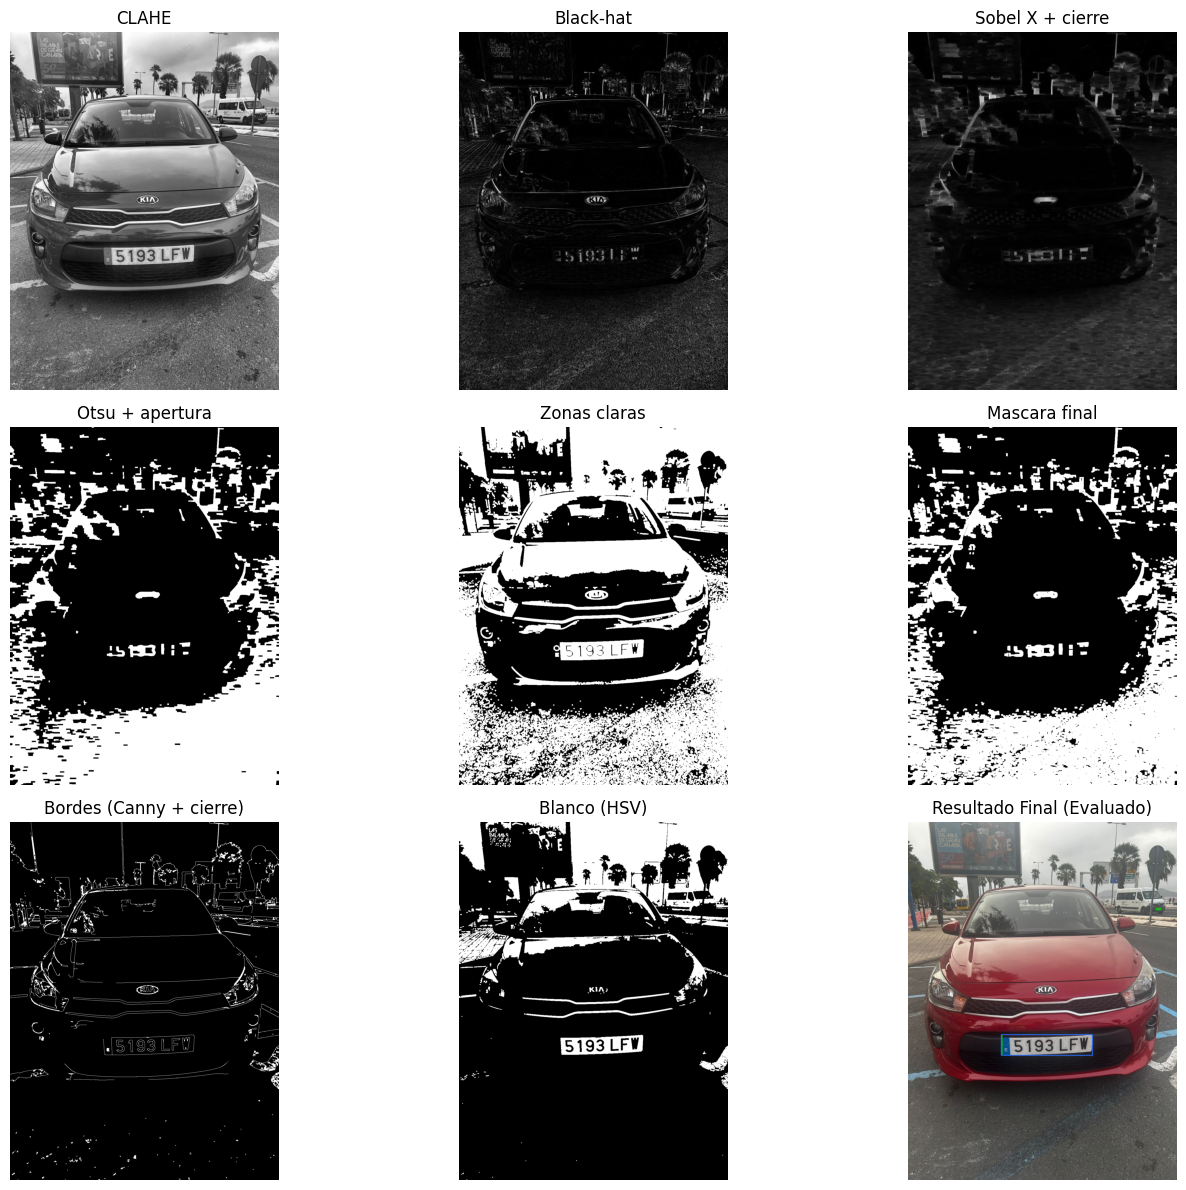

In [108]:
def mostrar_pasos_intermedios(ruta, ancho=1100):
    img = cv2.imread(ruta)
    if img is None: return
    
    f = min(1.0, ancho / img.shape[1])
    peq = cv2.resize(img, None, fx=f, fy=f, interpolation=cv2.INTER_AREA)
    gris = cv2.cvtColor(peq, cv2.COLOR_BGR2GRAY)
    
    pasos = pasos_caracteres(gris)
    pasos["Bordes (Canny + cierre)"] = pasos_bordes(gris)
    pasos["Blanco (HSV)"] = mascara_blanco(peq)
    
    fig, ejes = plt.subplots(3, 3, figsize=(15, 12))
    for ax, (nombre, im) in zip(ejes.ravel(), pasos.items()):
        ax.imshow(im, cmap="gray")
        ax.set_title(nombre)
        ax.axis("off")
        
    dets = detectar_mejorado(img)
    gts = next((g for r, g in imagenes_test if r == ruta), [])
    
    ejes[2, 2].imshow(cv2.resize(dibujar_evaluacion(img, gts, dets), (peq.shape[1], peq.shape[0])))
    ejes[2, 2].set_title("Resultado Final (Evaluado)")
    ejes[2, 2].axis("off")
    plt.tight_layout()
    plt.show()

if imagenes_test:
    ruta_aleatoria = random.choice([r for r, g in imagenes_test if g])
    print("Mostrando pasos intermedios...")
    mostrar_pasos_intermedios(ruta_aleatoria)

### Análisis visual del procesamiento

Al observar la cuadrícula de 3x3, podemos entender perfectamente cómo el algoritmo va "esculpiendo" la imagen paso a paso mediante filtros morfológicos hasta aislar la matrícula:

*   **CLAHE:** La imagen pasa a escala de grises y se ecualiza la luz. Vemos que el contraste aumenta muchísimo, haciendo que la matrícula destaque tanto si está a la sombra como a pleno sol.
*   **Black-hat:** La imagen se vuelve casi completamente negra. Solo brillan los pequeños detalles que originalmente eran más oscuros que su entorno (las letras y números de la placa, y las rendijas del radiador del coche).
*   **Sobel X + cierre:** Aquí el algoritmo busca líneas verticales y las emborrona horizontalmente. Vemos cómo los caracteres individuales de la matrícula se han "derretido" y fusionado, formando una única mancha rectangular grisácea.
*   **Otsu + apertura & Zonas claras:** El algoritmo transforma la imagen a blanco y negro puro. En "Otsu", la mancha gris de antes se convierte en un bloque blanco. En "Zonas claras", resalta el fondo reflectante de la chapa y el color claro del coche.
*   **Mascara final:** Es el cruce de las pistas anteriores. Se queda solo con los bloques macizos que además coinciden con zonas claras. La matrícula ya es un bloque blanco muy evidente.
*   **Bordes (Canny + cierre):** Saca las siluetas. Vemos la imagen negra con finas líneas blancas perfilando el coche. El rectángulo exacto de la matrícula queda dibujado a la perfección.
*   **Blanco (HSV):** Aísla estrictamente los colores brillantes y sin saturación. Como el coche es oscuro en este ejemplo, la matrícula y el cielo saltan a la vista como formas blancas puras.
*   **Resultado Final:** Tras extraer los contornos rectangulares de las máscaras anteriores y contar sus caracteres internos, el algoritmo dibuja una caja **azul** (Acierto, $IoU \ge 0.5$) encajando perfectamente sobre la placa.

---

## Evaluación Completa en el Dataset de Test

Se evalúan las 385 imágenes vírgenes del conjunto de *Test*. Un acierto se cuantifica si la predicción principal obtiene un $IoU \ge 0.5$ respecto a las anotaciones reales (criterio estándar *mAP50*).

Evaluando 385 imágenes...

    ┌──────────────────────────────┬───────────┬─────────────┐
    │ MÉTRICA                      │ RESULTADO │ PROPORCIÓN  │
    ├──────────────────────────────┼───────────┼─────────────┤
    │ Éxito por imagen (top-1)     │     60.3% │      -      │
    │ Imágenes vacías acertadas    │      0.0% │      -      │
    │ Recall (matrículas halladas) │     40.3% │ (351/872)   │
    │ Recall matrículas >= 60 px   │     67.2% │ (287/427)   │
    │ Precisión (detecciones bien) │     46.6% │ (351/754)   │
    └──────────────────────────────┴───────────┴─────────────┘
    
Generando cuadrícula visual de muestras aleatorias...


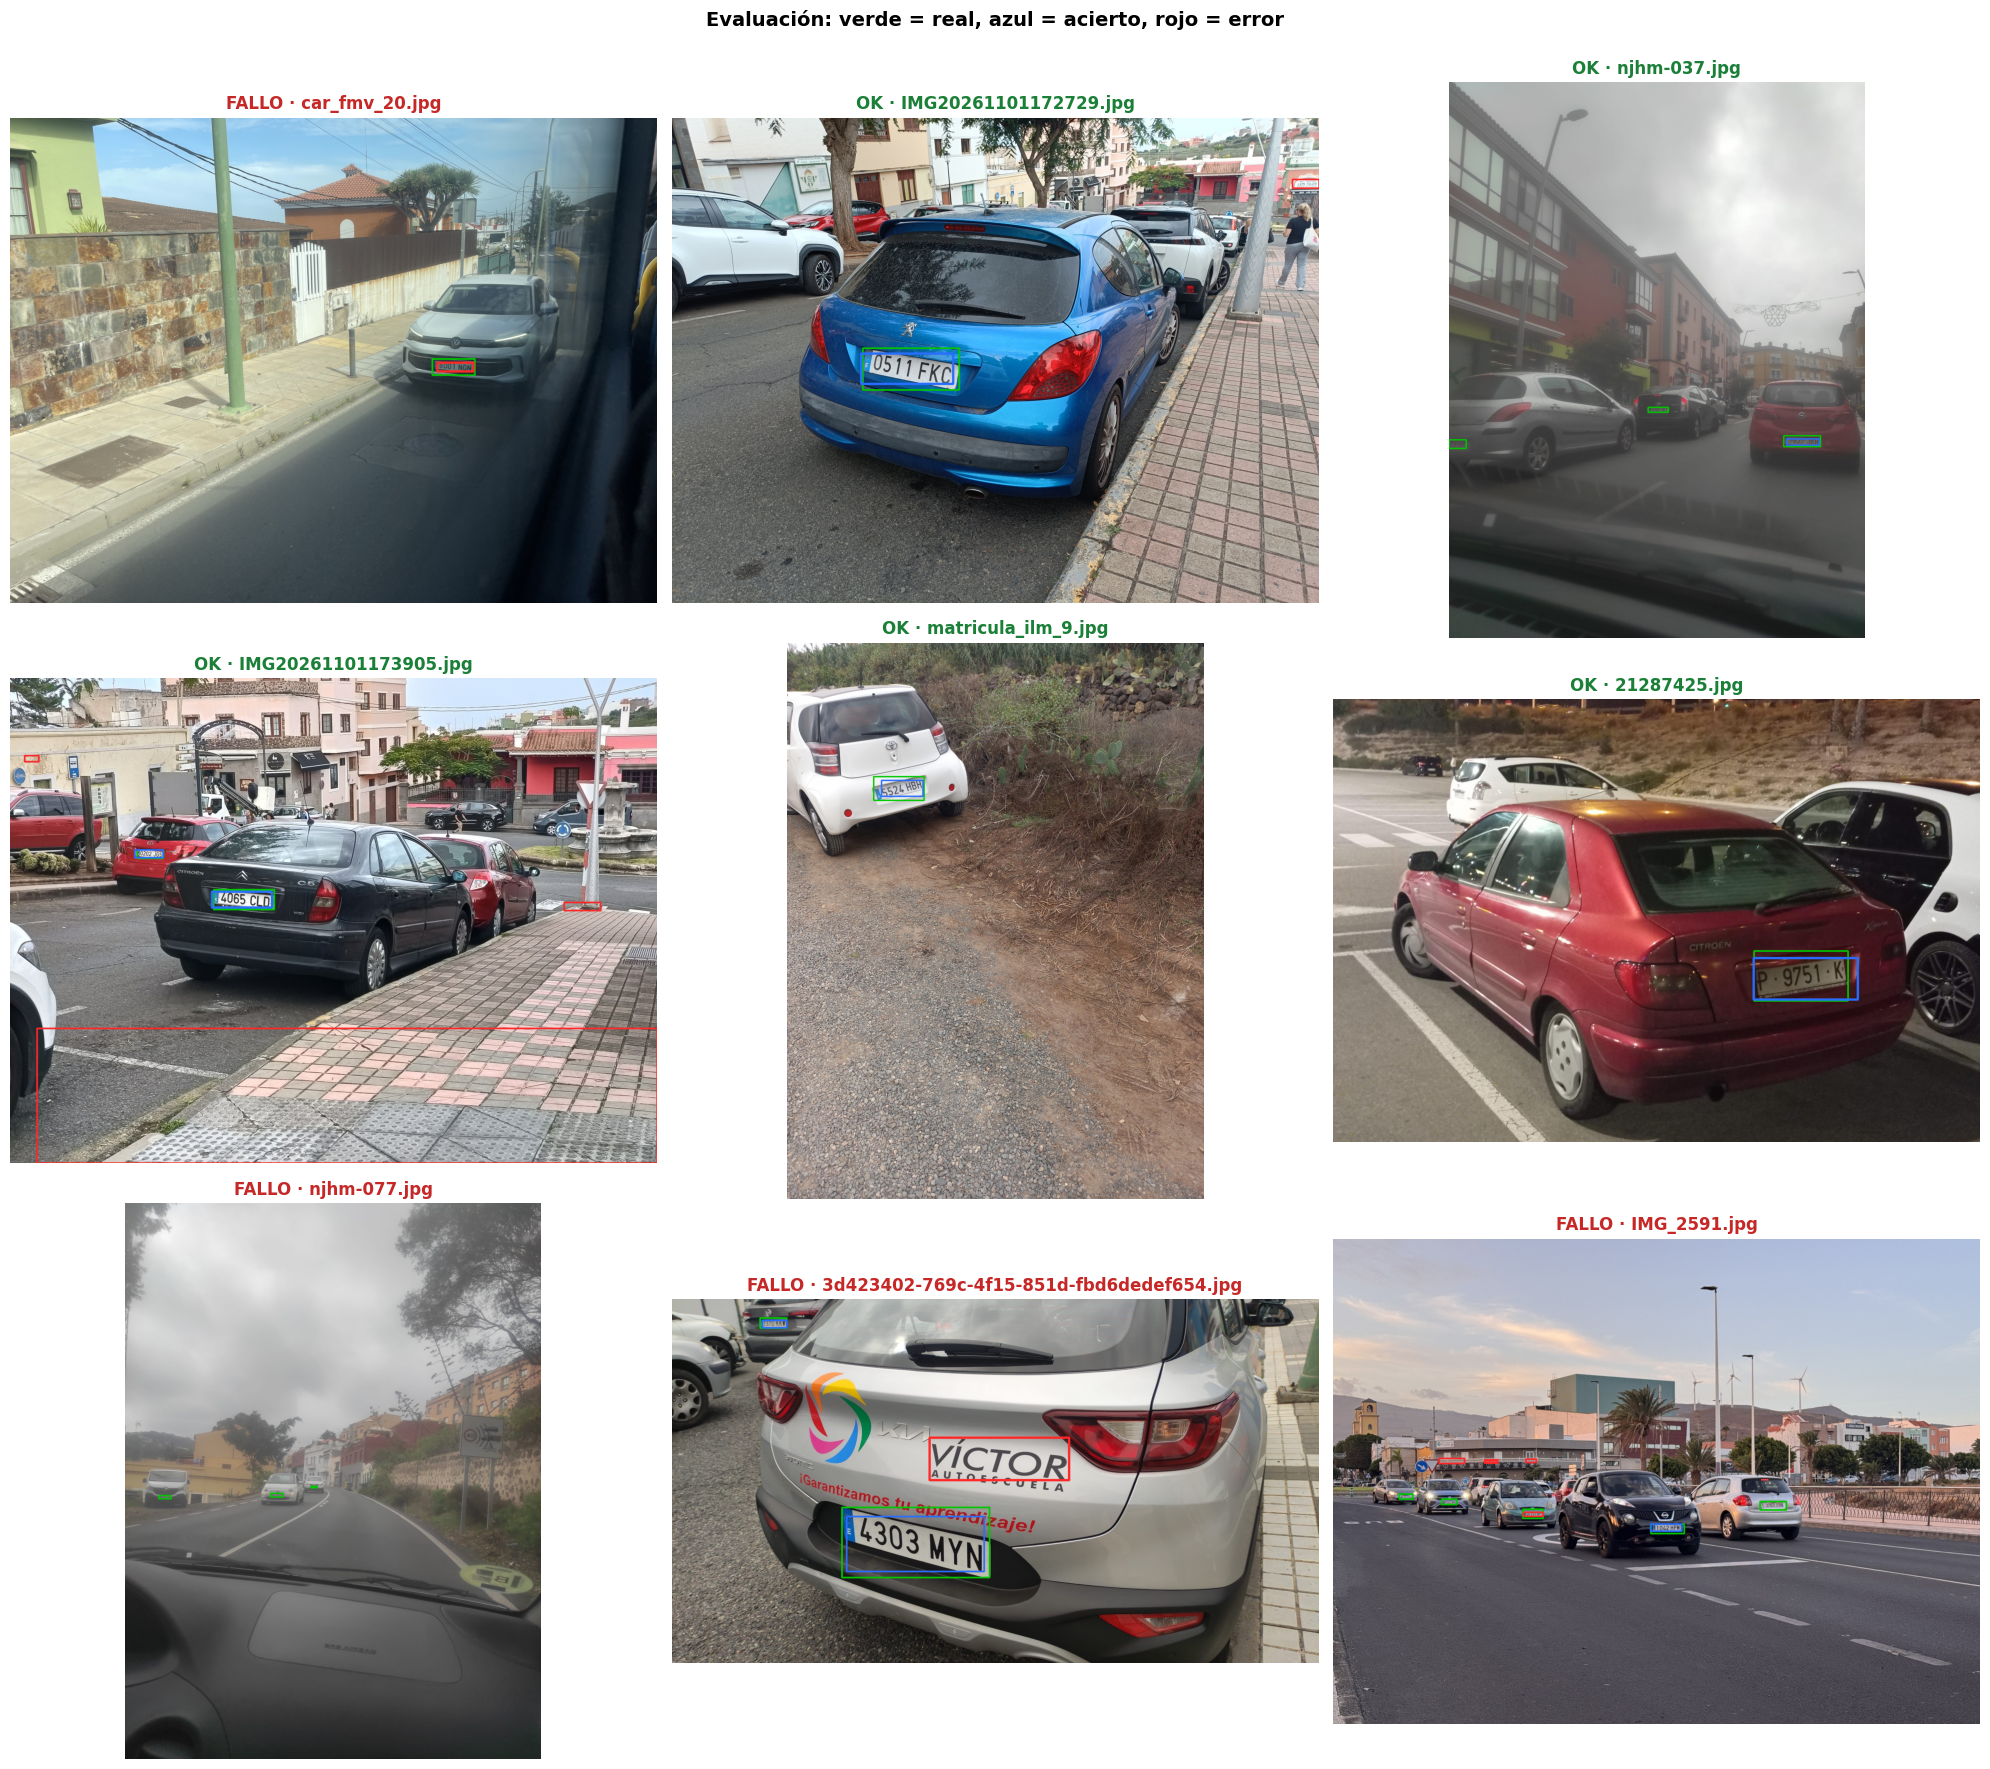

In [55]:
if imagenes_test:
    print(f"Evaluando {len(imagenes_test)} imágenes...")

    exitos = 0
    exitos_vacias = 0
    tot_gt = 0
    hallados = 0
    tot_det = 0
    correctas = 0
    grandes = [0, 0]   # [halladas, total] con ancho >= 60 px

    for ruta, gts in imagenes_test:
        img = cv2.imread(ruta)
        if img is None:
            continue
            
        dets = detectar_mejorado(img)

        # Comprobación de éxito por imagen
        if not gts and not dets:
            exitos_vacias += 1
        elif dets:
            acierto_imagen = False
            for g in gts:
                if iou(dets[0], g) >= IOU_ACIERTO:
                    acierto_imagen = True
                    break
            if acierto_imagen:
                exitos += 1

        usadas = set()
        
        # Asignación de cada detección a su mejor coincidencia real
        for d in dets:
            mejor_k = None
            mejor_iou = -1.0
            
            for j in range(len(gts)):
                iou_actual = iou(d, gts[j])
                if iou_actual > mejor_iou:
                    mejor_iou = iou_actual
                    mejor_k = j
                    
            if mejor_k is not None:
                if mejor_k not in usadas:
                    if mejor_iou >= IOU_ACIERTO:
                        usadas.add(mejor_k)

        # Conteo de matrículas grandes
        for j, g in enumerate(gts):
            ancho_real = g[2] - g[0]
            if ancho_real >= 60:
                grandes[1] += 1
                if j in usadas:
                    grandes[0] += 1

        tot_gt += len(gts)
        hallados += len(usadas)
        tot_det += len(dets)
        correctas += len(usadas)

    # Resultados
    n = len(imagenes_test)
    p_exito = 100 * exitos / n
    p_vacias = 100 * exitos_vacias / n
    p_recall = 100 * hallados / max(1, tot_gt)
    p_grandes = 100 * grandes[0] / max(1, grandes[1])
    p_precision = 100 * correctas / max(1, tot_det)

    tabla = f"""
    ┌──────────────────────────────┬───────────┬─────────────┐
    │ MÉTRICA                      │ RESULTADO │ PROPORCIÓN  │
    ├──────────────────────────────┼───────────┼─────────────┤
    │ Éxito por imagen (top-1)     │ {p_exito:8.1f}% │      -      │
    │ Imágenes vacías acertadas    │ {p_vacias:8.1f}% │      -      │
    │ Recall (matrículas halladas) │ {p_recall:8.1f}% │ ({hallados}/{tot_gt})   │
    │ Recall matrículas >= 60 px   │ {p_grandes:8.1f}% │ ({grandes[0]}/{grandes[1]})   │
    │ Precisión (detecciones bien) │ {p_precision:8.1f}% │ ({correctas}/{tot_det})   │
    └──────────────────────────────┴───────────┴─────────────┘
    """
    print(tabla)

    # Mostrar cuadrícula 3x3
    print("Generando cuadrícula visual de muestras aleatorias...")
    num_imagenes = 9
    elegidas = random.sample(imagenes_test, min(num_imagenes, n))

    filas_fig = (len(elegidas) + 2) // 3
    fig, ejes = plt.subplots(filas_fig, 3, figsize=(20, 6 * filas_fig))
    ejes = np.atleast_2d(ejes)

    for i, (ruta, gts) in enumerate(elegidas):
        img = cv2.imread(ruta)
        dets = detectar_mejorado(img)
        
        top_ok = False
        if dets:
            for g in gts:
                if iou(dets[0], g) >= IOU_ACIERTO:
                    top_ok = True
                    break

        vis = dibujar_evaluacion(img, gts, dets)
        ax = ejes[i // 3, i % 3]
        ax.imshow(vis)
        
        if top_ok:
            texto_titulo = "OK"
            color_titulo = "#1a7f37"
        else:
            texto_titulo = "FALLO"
            color_titulo = "#c62828"
            
        ax.set_title(f"{texto_titulo} · {Path(ruta).name}", color=color_titulo, fontweight="bold")
        ax.axis("off")

    for ax in ejes.ravel()[len(elegidas):]:
        ax.axis("off")

    fig.suptitle("Evaluación: verde = real, azul = acierto, rojo = error", fontsize=14, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.98])
    plt.show()

### Análisis de Resultados

Al evaluar el algoritmo sobre las 385 imágenes de test, el resultado más representativo de su comportamiento es el **Recall general del 40.3%** (351 matrículas halladas de un total de 872). Esta cifra es completamente normal y esperable en métodos puramente basados en contornos. Al analizar la imagen píxel a píxel sin entender el contexto, el algoritmo pierde las matrículas lejanas o en baja resolución, ya que los cierres morfológicos acaban fusionando las letras en un manchón y arruinan la verificación interna de la función `contar_caracteres`.

Sin embargo, desglosando el resto de métricas, el comportamiento del algoritmo tiene mucho sentido y demuestra ser bastante robusto:

* **El tamaño es clave (Recall $\ge$ 60 px):** Si nos fijamos únicamente en las matrículas grandes, el acierto se dispara al **67.2%** (287 de 427). Esto confirma que el código está bien diseñado y es muy eficaz, pero exige una resolución mínima indispensable para poder extraer la geometría de los caracteres.
* **Falsos positivos (Precisión del 46.6%):** El algoritmo dibuja bastantes cajas erróneas. A pesar de aplicar restricciones de proporción y color, en la calle existen multitud de elementos (faros, señales, calandras estriadas o reflejos) que imitan la forma de una placa y engañan a los filtros de Canny y HSV, como se observa en algunos recuadros rojos de la cuadrícula de evaluación.

* **Éxito por imagen (60.3%):** Pese a perder las matrículas pequeñas, el método logra encontrar al menos la matrícula principal en el 60.3% de las fotografías. Es una tasa alta para un método tradicional, lograda gracias a procesar la imagen a varios tamaños (multiescala) y cruzar tres pistas distintas (texto, bordes y color).

En resumen, el procesamiento digital de imagen proporciona un algoritmo veloz y muy preciso para primeros planos, pero sufre inevitablemente ante la variabilidad geométrica del mundo real, como las oclusiones o las escalas diminutas.

---